# 電流値を変化させた時の励磁磁場分布の調査  
作成日：2026年09月02日  
作成者：上杉 健太

In [1]:
# conf
project_name = "261016_励磁コイル"

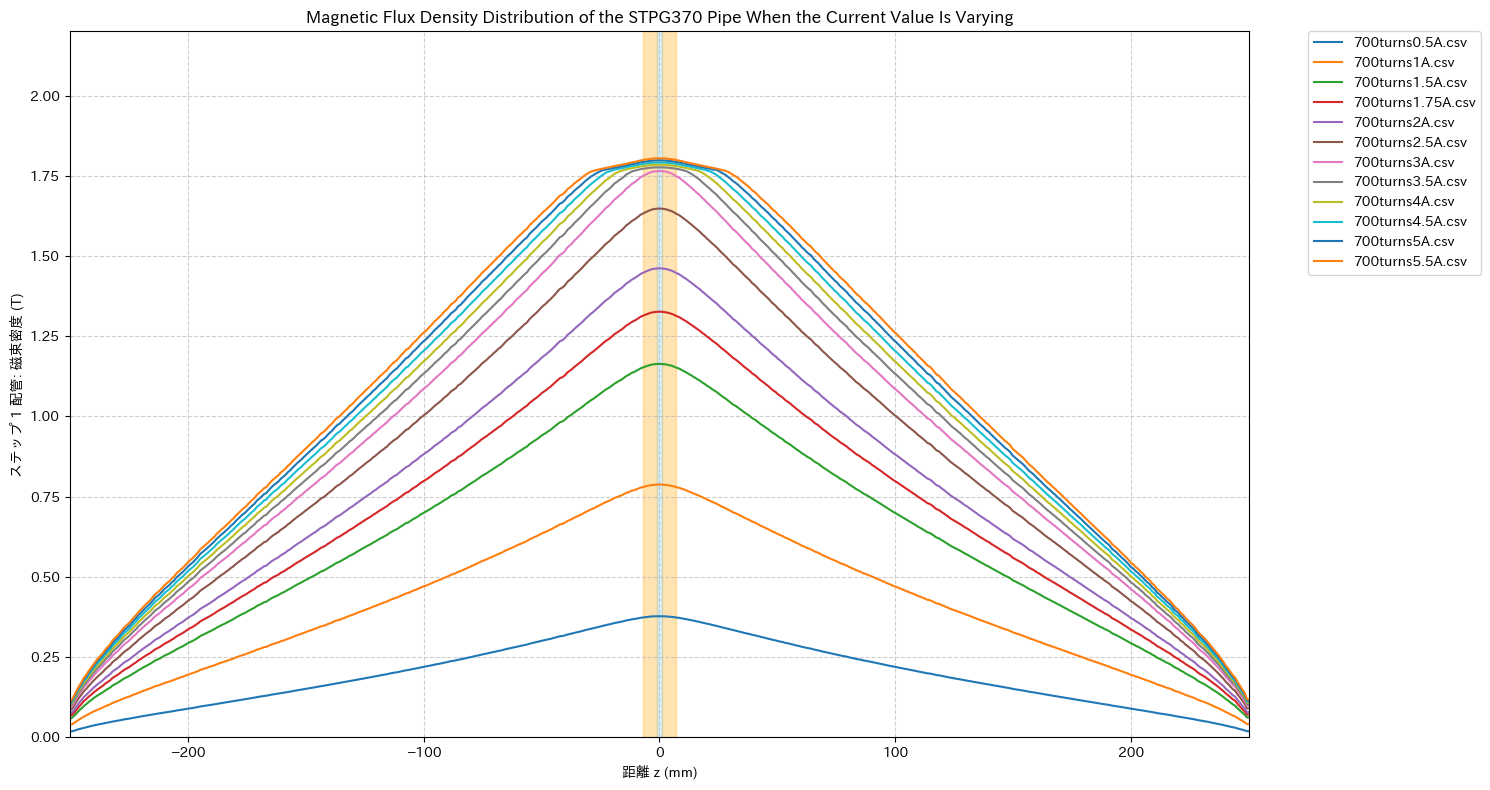

処理完了: 12 件のファイルをプロットしました。


In [2]:
import glob
import io
import os
import platform
import re
import matplotlib.pyplot as plt
import pandas as pd

# 日本語フォントの設定 (Windows / Mac / Linux 互換)
try:
    import japanize_matplotlib
except ImportError:
    system = platform.system()
    if system == 'Darwin':
        plt.rcParams['font.family'] = 'Hiragino Sans'
    elif system == 'Windows':
        plt.rcParams['font.family'] = 'MS Gothic'
    else:
        plt.rcParams['font.family'] = 'DejaVu Sans'

# 設定
# JMAGの座標系 (0 ~ 500 mm) でコイル中心は 250 mm
# center_origin = True の場合、中心 (250 mm) を原点 0 にシフトして COMSOL (-250 ~ 250 mm) と統一
center_origin = True
center_offset = 250.0 if center_origin else 0.0

file_pattern = f"source/{project_name}/*.csv"
raw_files = glob.glob(file_pattern, recursive=True)

# 電流値順 (0.5A, 1A, 1.5A, ...) に自然順ソート
def extract_current(filepath):
    m = re.search(r'([0-9.]+)\s*A', os.path.basename(filepath), re.IGNORECASE)
    return float(m.group(1)) if m else 0.0

csv_files = sorted(raw_files, key=extract_current)

plt.figure(figsize=(15, 8))

# 指定範囲の背景色を設定 (データ線の下に表示されるよう先に描画)
if center_origin:
    plt.axvspan(-7, -1, color='orange', alpha=0.3)
    plt.axvspan(1, 7, color='orange', alpha=0.3)
    plt.axvspan(-1, 1, color='skyblue', alpha=0.3)
else:
    plt.axvspan(250 - 7, 250 - 1, color='orange', alpha=0.3)
    plt.axvspan(250 + 1, 250 + 7, color='orange', alpha=0.3)
    plt.axvspan(250 - 1, 250 + 1, color='skyblue', alpha=0.3)

def load_jmag_csv(file_path):
    """
    JMAG CSVファイルを読み込む関数
    - Shift-JIS (cp932) および UTF-8 の両方に対応
    - 複数セクション (空気領域/配管) がある場合も「配管: 磁束密度」を自動抽出
    - ヘッダーなしファイル (4Aなど) や [ケース 1] 付きヘッダー (1.75Aなど) にも自動対応
    """
    lines = None
    for enc in ['cp932', 'shift_jis', 'utf-8-sig', 'utf-8']:
        try:
            with open(file_path, 'r', encoding=enc) as f:
                lines = f.readlines()
            break
        except (UnicodeDecodeError, LookupError):
            continue

    if lines is None:
        raise ValueError(f"文字コードを自動判別できませんでした: {file_path}")

    # 「配管」かつ「磁束密度」が含まれるヘッダー行を検索
    pipe_header_idx = None
    for idx, line in enumerate(lines):
        if '配管' in line and '磁束密度' in line:
            pipe_header_idx = idx
            break

    if pipe_header_idx is not None:
        csv_data = ''.join(lines[pipe_header_idx:])
        df = pd.read_csv(io.StringIO(csv_data))
        df.columns = df.columns.str.strip()

        # 距離列と磁束密度列を抽出
        x_col = next((c for c in df.columns if '距離' in c), df.columns[0])
        y_col = next((c for c in df.columns if '磁束密度' in c), df.columns[1])

        x_vals = pd.to_numeric(df[x_col], errors='coerce')
        y_vals = pd.to_numeric(df[y_col], errors='coerce')
        return pd.DataFrame({'x': x_vals, 'y': y_vals}).dropna()
    else:
        # ヘッダー行がない場合のフォールバック (数値データで開始しているか判定)
        first_line = lines[0].strip() if lines else ""
        first_tokens = first_line.split(',')
        try:
            float(first_tokens[0])
            float(first_tokens[1])
            # ヘッダーなしCSV
            df = pd.read_csv(io.StringIO(''.join(lines)), header=None)
            x_vals = pd.to_numeric(df[0], errors='coerce')
            y_vals = pd.to_numeric(df[1], errors='coerce')
            return pd.DataFrame({'x': x_vals, 'y': y_vals}).dropna()
        except (ValueError, IndexError):
            # 通常読み込み
            df = pd.read_csv(io.StringIO(''.join(lines)))
            df.columns = df.columns.str.strip()
            x_col = next((c for c in df.columns if '距離' in c), df.columns[0])
            y_col = next((c for c in df.columns if '磁束密度' in c), df.columns[1])
            x_vals = pd.to_numeric(df[x_col], errors='coerce')
            y_vals = pd.to_numeric(df[y_col], errors='coerce')
            return pd.DataFrame({'x': x_vals, 'y': y_vals}).dropna()

plotted_count = 0

for file_path in csv_files:
    if not os.path.isfile(file_path):
        continue

    filename = os.path.basename(file_path)
    try:
        df = load_jmag_csv(file_path)
        if df.empty:
            print(f"スキップ: {filename} (有効なデータ行がありません)")
            continue

        df = df.sort_values(by='x', ascending=True)
        x_plot = df['x'] - center_offset
        plt.plot(x_plot, df['y'], label=filename)
        plotted_count += 1

    except Exception as e:
        print(f"エラー発生 ({filename}): {e}")

if plotted_count > 0:
    plt.xlabel('距離 z (mm)' if center_origin else '距離 (mm)')
    plt.ylabel('ステップ 1 配管: 磁束密度 (T)')
    plt.title("Magnetic Flux Density Distribution of the STPG370 Pipe When the Current Value Is Varying")

    if center_origin:
        plt.xlim(-250, 250)
    else:
        plt.xlim(0, 500)
    plt.ylim(0, 2.2)

    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
    plt.tight_layout()

    # 出力先ディレクトリの自動作成
    output_dir = f"./results/{project_name}"
    os.makedirs(output_dir, exist_ok=True)
    plt.savefig(f"{output_dir}/jmag_comparison.png", dpi=300)
    plt.savefig(f"{output_dir}/comsol_comparison.png", dpi=300)
    plt.show()
    print(f"処理完了: {plotted_count} 件のファイルをプロットしました。")
else:
    print("有効なデータが見つかりませんでした。")